# 02 · Vendor Performance Analysis

Uses the `vendor_sales_summary` table (one row per vendor + product) built by
`src/get_vendor_summary.py` to answer procurement questions:
which vendors and brands drive sales, where we depend too much on a few suppliers,
whether bulk buying pays off, which stock moves slowly and how much cash is stuck in it.

Run cell-by-cell in VS Code or the whole file with
`python analysis/02_vendor_performance_analysis.py` (charts are saved to `reports/figures/`).

In [1]:
import sqlite3
import sys
import warnings
from pathlib import Path

import matplotlib

if "ipykernel" not in sys.modules:  # plain `python` run: save charts without opening windows
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from IPython.display import display
from scipy.stats import ttest_ind

warnings.filterwarnings("ignore")

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(name: str) -> None:
    """Save the current chart to reports/figures and show it."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()
    plt.close()


def format_dollars(value: float) -> str:
    """12_345_678 -> '12.35M', 12_345 -> '12.35K'."""
    if value >= 1_000_000:
        return f"{value / 1_000_000:.2f}M"
    if value >= 1_000:
        return f"{value / 1_000:.2f}K"
    return f"{value:.2f}"


conn = sqlite3.connect(ROOT / "inventory.db")

## Load the summary table

In [2]:
df = pd.read_sql_query("SELECT * FROM vendor_sales_summary", conn)
print(df.shape)
display(df.head())

(10692, 18)


,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
0,1128,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750.0,145080,3811251.60,142049.0,5.101920e+06,672819.31,260999.20,19325.145490,1290667.91,25.297693,0.979108,1.338647
1,4425,MARTIGNETTI COMPANIES,3405,Tito's Handmade Vodka,23.19,28.99,1750.0,164038,3804041.22,160247.0,4.819073e+06,561512.37,294438.66,19787.629629,1015032.27,21.062810,0.976890,1.266830
2,17035,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750.0,187407,3418303.68,187140.0,4.538121e+06,461140.15,343854.07,17539.246213,1119816.92,24.675786,0.998575,1.327594
3,3960,DIAGEO NORTH AMERICA INC,4261,Capt Morgan Spiced Rum,16.17,22.99,1750.0,201682,3261197.94,200412.0,4.475973e+06,420050.01,368242.80,16448.897151,1214774.94,27.139908,0.993703,1.372493
4,3960,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750.0,138109,3023206.01,135838.0,4.223108e+06,545778.28,249587.83,15248.508566,1199901.61,28.412764,0.983556,1.396897


## Exploratory Data Analysis
Earlier (notebook 01) we studied the raw tables and built this summary. Now we look at the
distribution of each column to spot patterns, anomalies and data-quality issues.

In [3]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
VendorNumber,10692.0,10650.649458,18753.519148,2.000000,3951.000000,7153.000000,9552.000000,2.013590e+05
Brand,10692.0,18039.228769,12662.187074,58.000000,5793.500000,18761.500000,25514.250000,9.063100e+04
PurchasePrice,10692.0,24.385303,109.269375,0.360000,6.840000,10.455000,19.482500,5.681810e+03
ActualPrice,10692.0,35.643671,148.246016,0.490000,10.990000,15.990000,28.990000,7.499990e+03
Volume,10692.0,847.360550,664.309212,50.000000,750.000000,750.000000,750.000000,2.000000e+04
TotalPurchaseQuantity,10692.0,3140.886831,11095.086769,1.000000,36.000000,262.000000,1975.750000,3.376600e+05
TotalPurchaseDollars,10692.0,30106.693372,123067.799627,0.710000,453.457500,3655.465000,20738.245000,3.811252e+06
TotalSalesQuantity,10692.0,3077.482136,10952.851391,0.000000,33.000000,261.000000,1929.250000,3.349390e+05
TotalSalesDollars,10692.0,42239.074419,167655.265984,0.000000,729.220000,5298.045000,28396.915000,5.101920e+06
TotalSalesPrice,10692.0,18793.783627,44952.773386,0.000000,289.710000,2857.800000,16059.562500,6.728193e+05


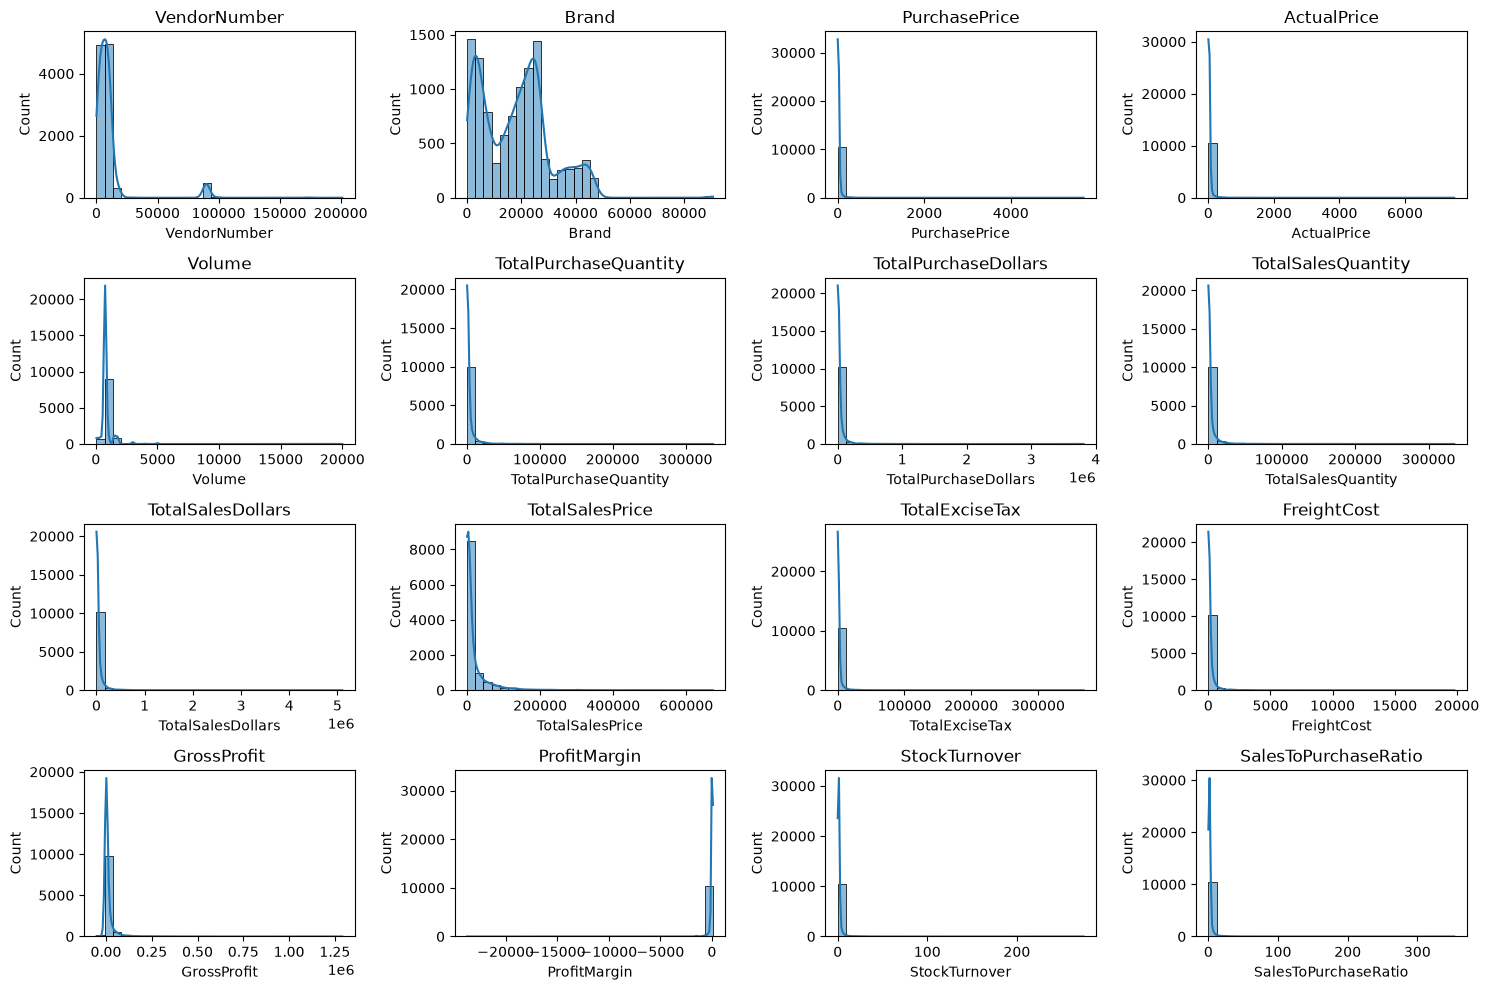

In [4]:
numerical_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(col)
plt.tight_layout()
save("01_distributions_raw")

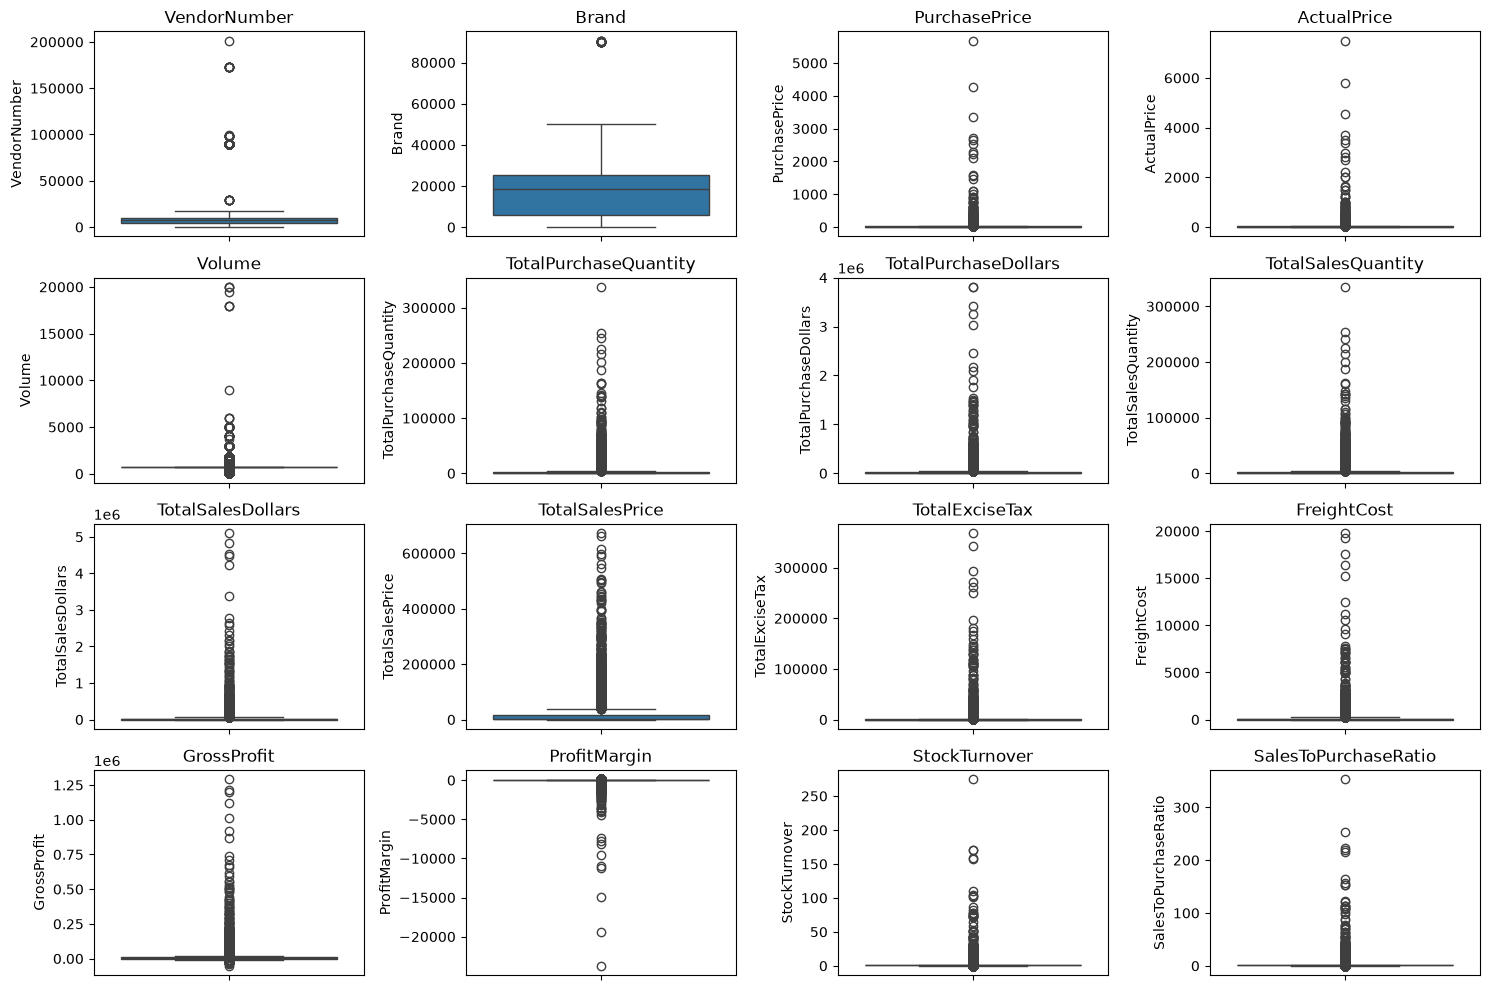

In [5]:
# Outlier detection with boxplots
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
save("02_boxplots_outliers")

### Summary statistics insights
**Negative and zero values**
- **Gross Profit** min is about −$52K → some products sell at a loss (high cost or discounts).
- **Profit Margin** is blank for products with zero sales, and negative for loss-makers.
- **Total Sales Quantity / Dollars** min is 0 → products bought but never sold (slow or obsolete stock).

**Outliers (very high standard deviations)**
- **Purchase / Actual Price** max ($5,681 / $7,500) vs mean ($24 / $36) → premium products.
- **Freight Cost** varies hugely → bulk shipments vs small orders.
- **Stock Turnover** ranges 0 → 274.5: some products sell fast, others sit on shelves.
  Above 1 means more was sold than bought in 2024 (sold from opening stock).

## Remove inconsistent rows
Keep only products that were sold and made a profit (drops losses, zero-sales rows and blanks).

In [6]:
df = pd.read_sql_query(
    """SELECT *
       FROM vendor_sales_summary
       WHERE GrossProfit > 0
         AND ProfitMargin > 0
         AND TotalSalesQuantity > 0""",
    conn,
)
print(f"Rows after filtering: {len(df):,}  |  vendors: {df['VendorName'].nunique()}")

Rows after filtering: 8,564  |  vendors: 119


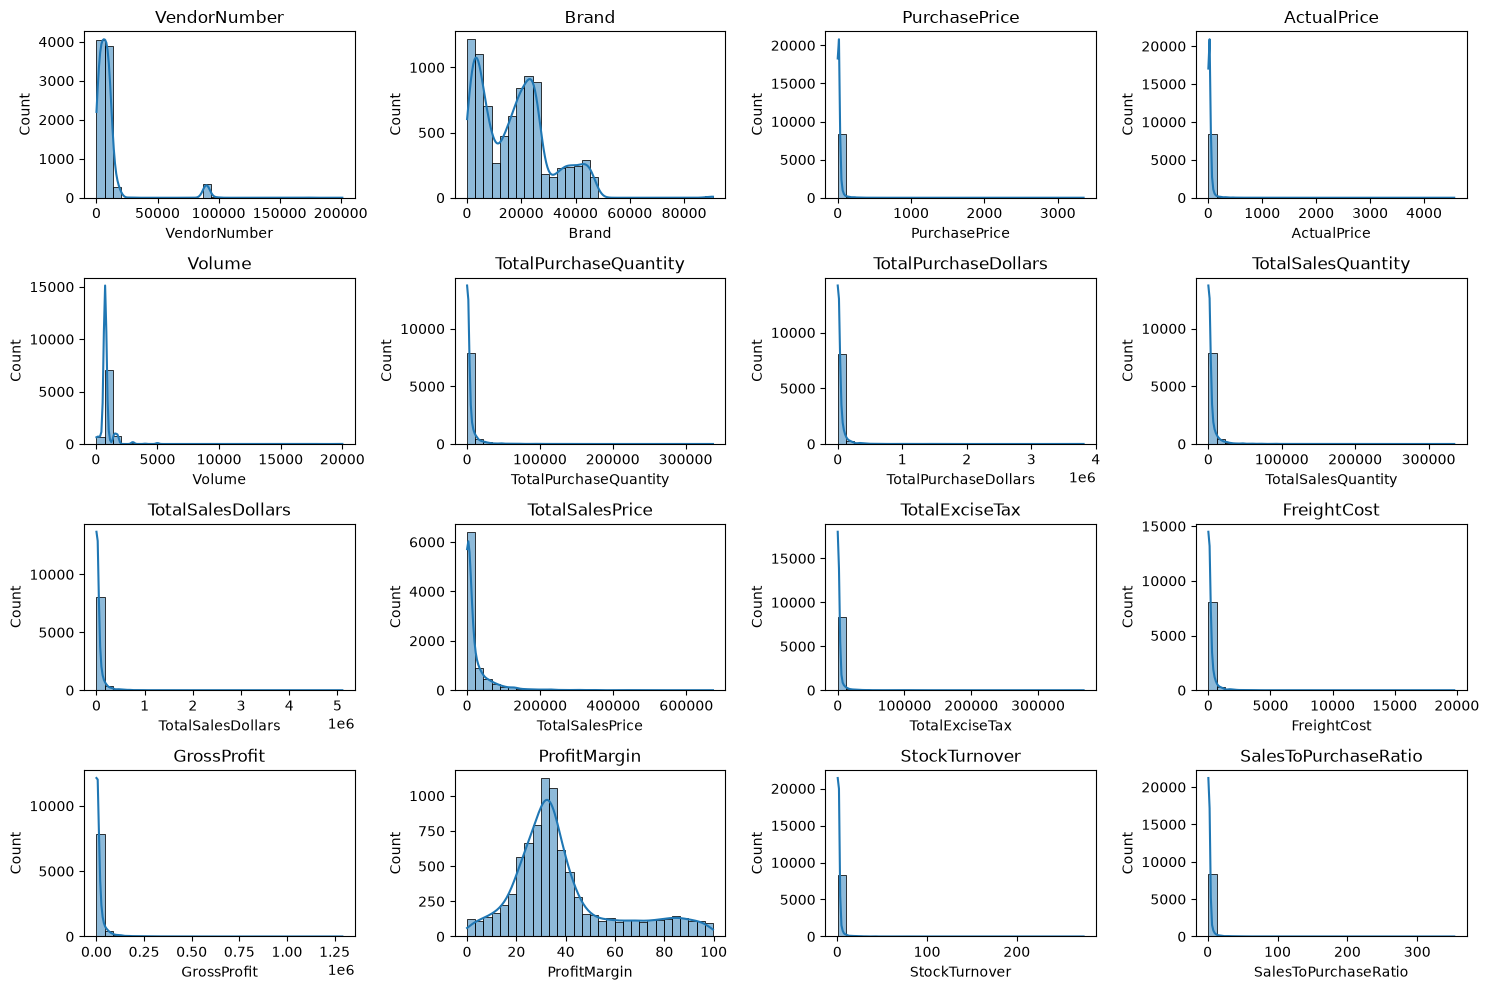

In [7]:
numerical_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(col)
plt.tight_layout()
save("03_distributions_clean")

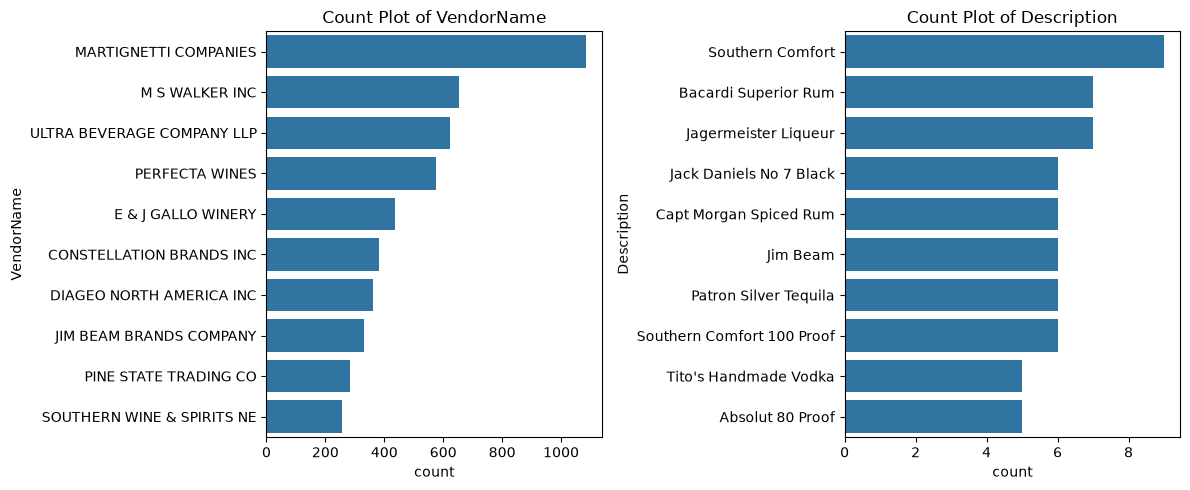

In [8]:
# Most frequent vendors and products (by number of product rows)
categorical_cols = ["VendorName", "Description"]
plt.figure(figsize=(12, 5))
for i, col in enumerate(categorical_cols):
    plt.subplot(1, 2, i + 1)
    sns.countplot(y=df[col], order=df[col].value_counts().index[:10])
    plt.title(f"Count Plot of {col}")
plt.tight_layout()
save("04_top_categories")

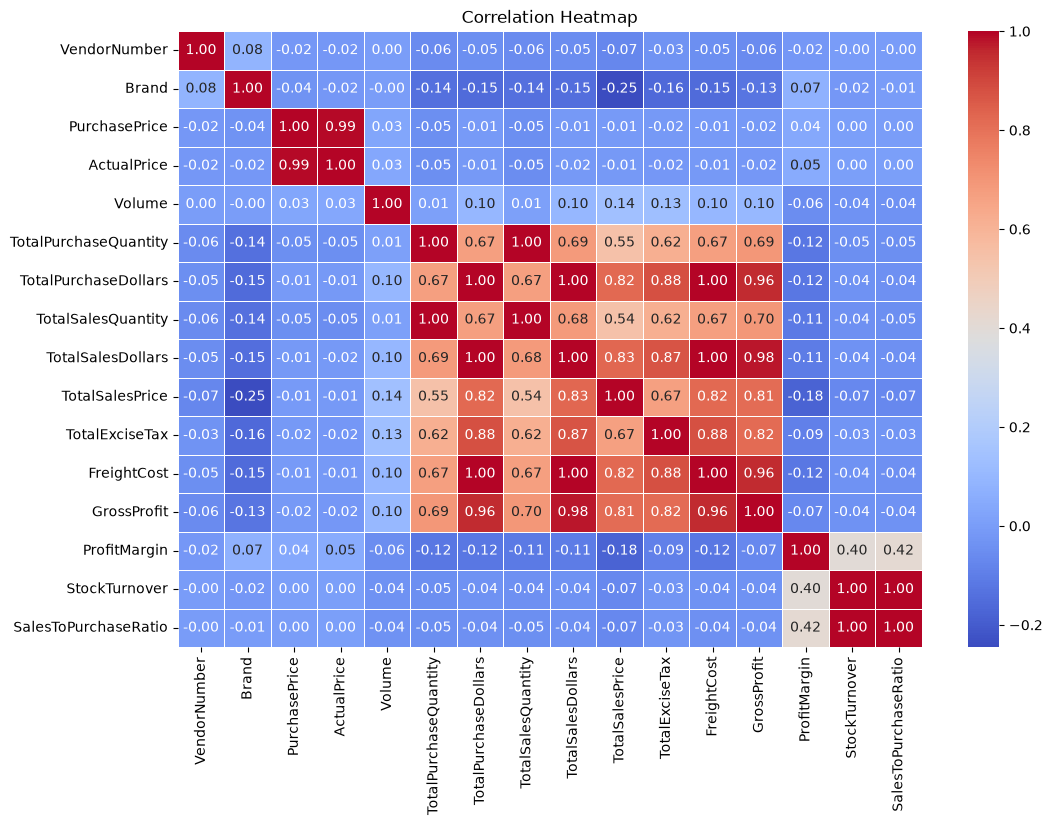

In [9]:
plt.figure(figsize=(12, 8))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
save("05_correlation_heatmap")

### Correlation insights
- **PurchasePrice** barely correlates with total sales $ or gross profit → price alone
  doesn't drive revenue or profit.
- **Purchase quantity vs sales quantity ≈ 0.999** → what we buy, we largely sell.
- **Profit margin vs total sales price** is negative → higher-priced lines carry thinner margins
  (competitive pricing).
- **StockTurnover** has a weak negative link with profit and margin → selling faster
  doesn't automatically mean more profit.

## Q1 · Which brands need promotion or price changes?
Brands with **low sales** (bottom 15%) but **high profit margins** (top 15%) — customers pay
well for them, they just don't sell enough.

In [10]:
brand_performance = df.groupby("Description").agg(
    {"TotalSalesDollars": "sum", "ProfitMargin": "mean"}
).reset_index()

low_sales_threshold = brand_performance["TotalSalesDollars"].quantile(0.15)
high_margin_threshold = brand_performance["ProfitMargin"].quantile(0.85)
print(f"Low sales threshold: ${low_sales_threshold:,.2f} | High margin threshold: {high_margin_threshold:.2f}%")

target_brands = brand_performance[
    (brand_performance["TotalSalesDollars"] <= low_sales_threshold)
    & (brand_performance["ProfitMargin"] >= high_margin_threshold)
]
print(f"Brands with low sales but high profit margins: {len(target_brands)}")
display(target_brands.sort_values("TotalSalesDollars"))

Low sales threshold: $560.30 | High margin threshold: 64.97%
Brands with low sales but high profit margins: 198


,Description,TotalSalesDollars,ProfitMargin
6199,Santa Rita Organic Svgn Bl,9.99,66.466466
2369,Debauchery Pnt Nr,11.58,65.975820
2070,Concannon Glen Ellen Wh Zin,15.95,83.448276
2188,Crown Royal Apple,27.86,89.806174
6237,Sauza Sprklg Wild Berry Marg,27.96,82.153076
...,...,...,...
5074,Nanbu Bijin Southern Beauty,535.68,76.747312
2271,Dad's Hat Rye Whiskey,538.89,81.851584
57,A Bichot Clos Marechaudes,539.94,67.740860
6245,Sbragia Home Ranch Merlot,549.75,66.444748


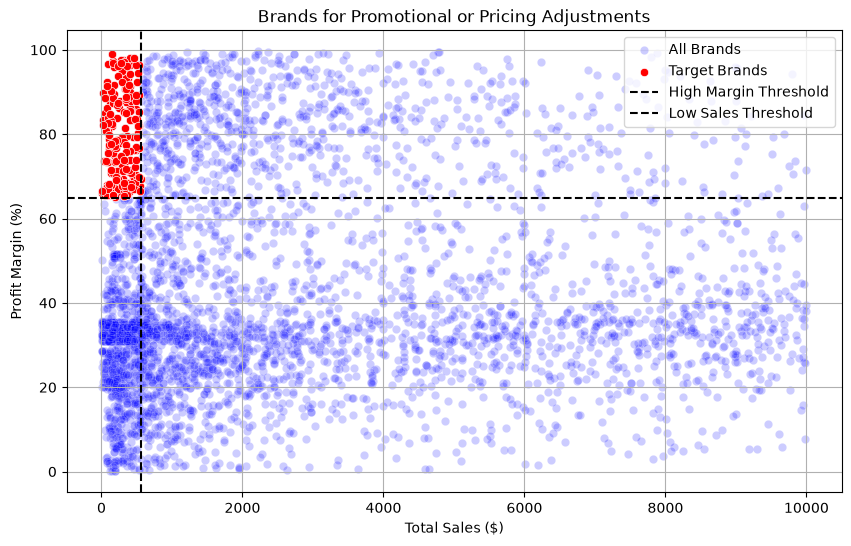

In [11]:
plot_brands = brand_performance[brand_performance["TotalSalesDollars"] < 10000]  # zoom in
plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_brands, x="TotalSalesDollars", y="ProfitMargin",
                color="blue", label="All Brands", alpha=0.2)
sns.scatterplot(data=target_brands, x="TotalSalesDollars", y="ProfitMargin",
                color="red", label="Target Brands")
plt.axhline(high_margin_threshold, linestyle="--", color="black", label="High Margin Threshold")
plt.axvline(low_sales_threshold, linestyle="--", color="black", label="Low Sales Threshold")
plt.xlabel("Total Sales ($)")
plt.ylabel("Profit Margin (%)")
plt.title("Brands for Promotional or Pricing Adjustments")
plt.legend()
plt.grid(True)
save("06_target_brands_scatter")

## Q2 · Which vendors and brands sell the most?

In [12]:
top_vendors_sales = df.groupby("VendorName")["TotalSalesDollars"].sum().nlargest(10)
top_brands_sales = df.groupby("Description")["TotalSalesDollars"].sum().nlargest(10)
display(top_vendors_sales.apply(format_dollars))
display(top_brands_sales.apply(format_dollars))

VendorName
DIAGEO NORTH AMERICA INC      67.99M
MARTIGNETTI COMPANIES         39.33M
PERNOD RICARD USA             32.06M
JIM BEAM BRANDS COMPANY       31.42M
BACARDI USA INC               24.85M
CONSTELLATION BRANDS INC      24.22M
E & J GALLO WINERY            18.40M
BROWN-FORMAN CORP             18.25M
ULTRA BEVERAGE COMPANY LLP    16.50M
M S WALKER INC                14.71M
Name: TotalSalesDollars, dtype: str

Description
Jack Daniels No 7 Black    7.96M
Tito's Handmade Vodka      7.40M
Grey Goose Vodka           7.21M
Capt Morgan Spiced Rum     6.36M
Absolut 80 Proof           6.24M
Jameson Irish Whiskey      5.72M
Ketel One Vodka            5.07M
Baileys Irish Cream        4.15M
Kahlua                     3.60M
Tanqueray                  3.46M
Name: TotalSalesDollars, dtype: str

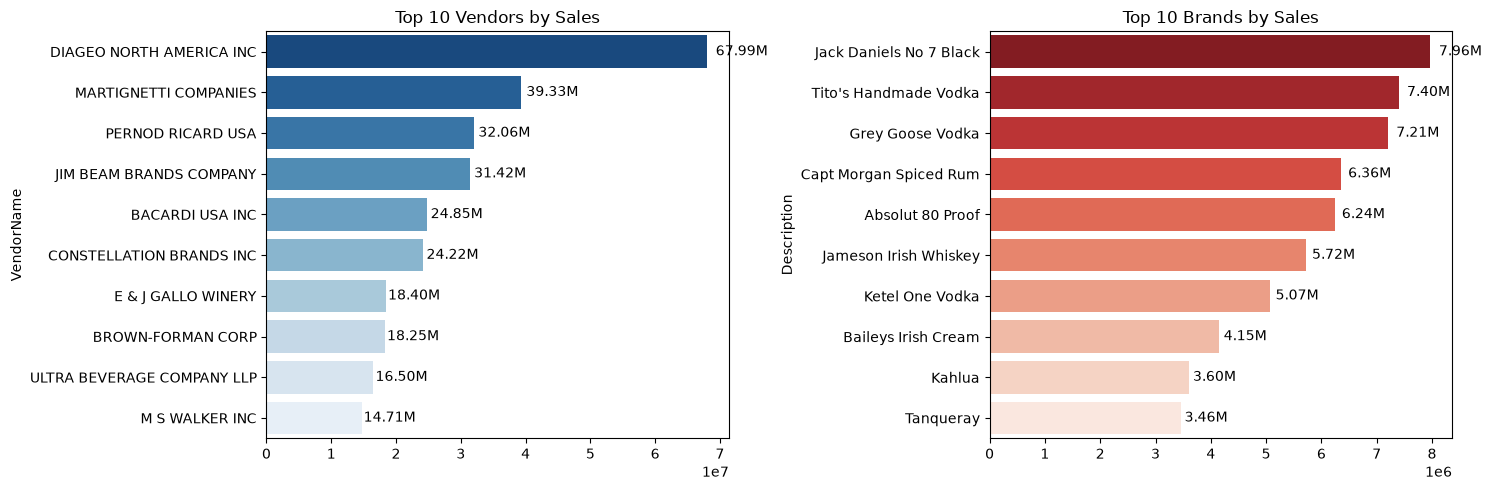

In [13]:
plt.figure(figsize=(15, 5))
for i, (series, title, palette) in enumerate([
    (top_vendors_sales, "Top 10 Vendors by Sales", "Blues_r"),
    (top_brands_sales, "Top 10 Brands by Sales", "Reds_r"),
]):
    plt.subplot(1, 2, i + 1)
    ax = sns.barplot(y=series.index.astype(str), x=series.values, palette=palette)
    plt.title(title)
    for bar in ax.patches:
        ax.text(bar.get_width() * 1.02, bar.get_y() + bar.get_height() / 2,
                format_dollars(bar.get_width()), ha="left", va="center", fontsize=10)
plt.tight_layout()
save("07_top_vendors_brands")

## Q3 · Which vendors take the biggest share of purchase spend?

In [14]:
vendor_performance = df.groupby("VendorName").agg(
    {"TotalPurchaseDollars": "sum", "GrossProfit": "sum", "TotalSalesDollars": "sum"}
).reset_index()
vendor_performance["PurchaseContribution%"] = (
    vendor_performance["TotalPurchaseDollars"] / vendor_performance["TotalPurchaseDollars"].sum() * 100
)
vendor_performance = vendor_performance.sort_values("PurchaseContribution%", ascending=False).round(2)

top_vendors = vendor_performance.head(10).copy()
top_vendors["CumulativeContribution%"] = top_vendors["PurchaseContribution%"].cumsum()

display_table = top_vendors.copy()
for col in ["TotalPurchaseDollars", "GrossProfit", "TotalSalesDollars"]:
    display_table[col] = display_table[col].apply(format_dollars)
display(display_table)

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%,CumulativeContribution%
25,DIAGEO NORTH AMERICA INC,50.10M,17.89M,67.99M,16.30,16.30
57,MARTIGNETTI COMPANIES,25.50M,13.83M,39.33M,8.30,24.60
68,PERNOD RICARD USA,23.85M,8.21M,32.06M,7.76,32.36
46,JIM BEAM BRANDS COMPANY,23.49M,7.93M,31.42M,7.64,40.00
6,BACARDI USA INC,17.43M,7.42M,24.85M,5.67,45.67
20,CONSTELLATION BRANDS INC,15.27M,8.95M,24.22M,4.97,50.64
11,BROWN-FORMAN CORP,13.24M,5.01M,18.25M,4.31,54.95
30,E & J GALLO WINERY,12.07M,6.33M,18.40M,3.93,58.88
106,ULTRA BEVERAGE COMPANY LLP,11.17M,5.34M,16.50M,3.63,62.51
53,M S WALKER INC,9.76M,4.94M,14.71M,3.18,65.69


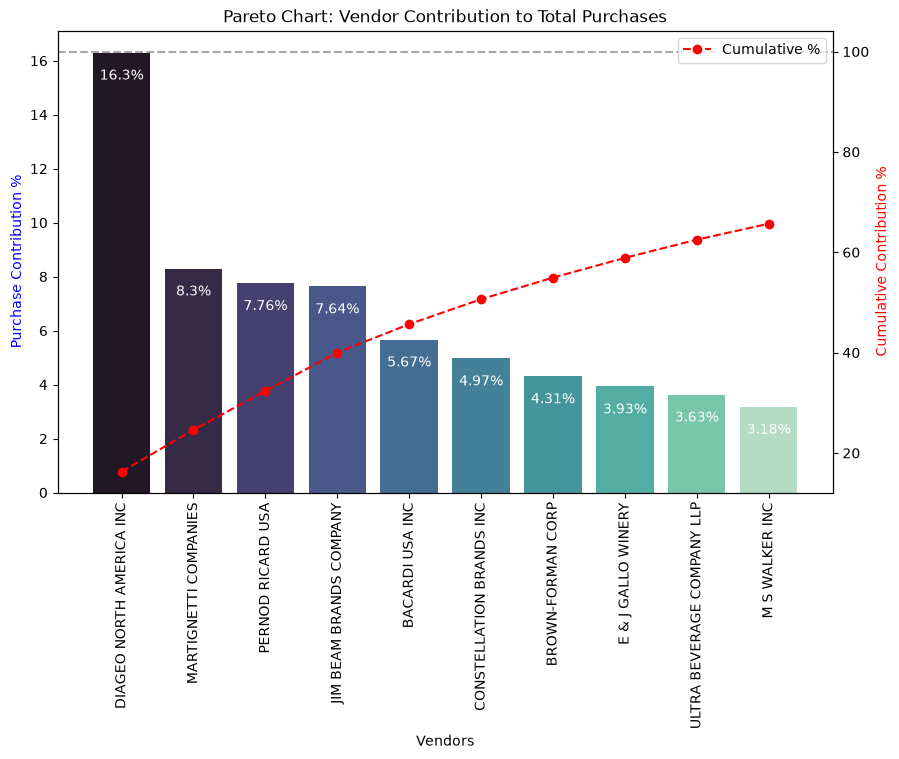

In [15]:
fig, ax1 = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_vendors["VendorName"], y=top_vendors["PurchaseContribution%"], palette="mako", ax=ax1)
for i, value in enumerate(top_vendors["PurchaseContribution%"]):
    ax1.text(i, value - 1, f"{value}%", ha="center", fontsize=10, color="white")
ax2 = ax1.twinx()
ax2.plot(top_vendors["VendorName"], top_vendors["CumulativeContribution%"], color="red",
         marker="o", linestyle="dashed", label="Cumulative %")
ax1.set_xticks(range(len(top_vendors)))
ax1.set_xticklabels(top_vendors["VendorName"], rotation=90)
ax1.set_ylabel("Purchase Contribution %", color="blue")
ax2.set_ylabel("Cumulative Contribution %", color="red")
ax1.set_xlabel("Vendors")
ax1.set_title("Pareto Chart: Vendor Contribution to Total Purchases")
ax2.axhline(y=100, color="gray", linestyle="dashed", alpha=0.7)
ax2.legend(loc="upper right")
save("08_pareto_vendor_purchases")

## Q4 · How dependent are we on the top vendors?

Total purchase contribution of top 10 vendors: 65.69%


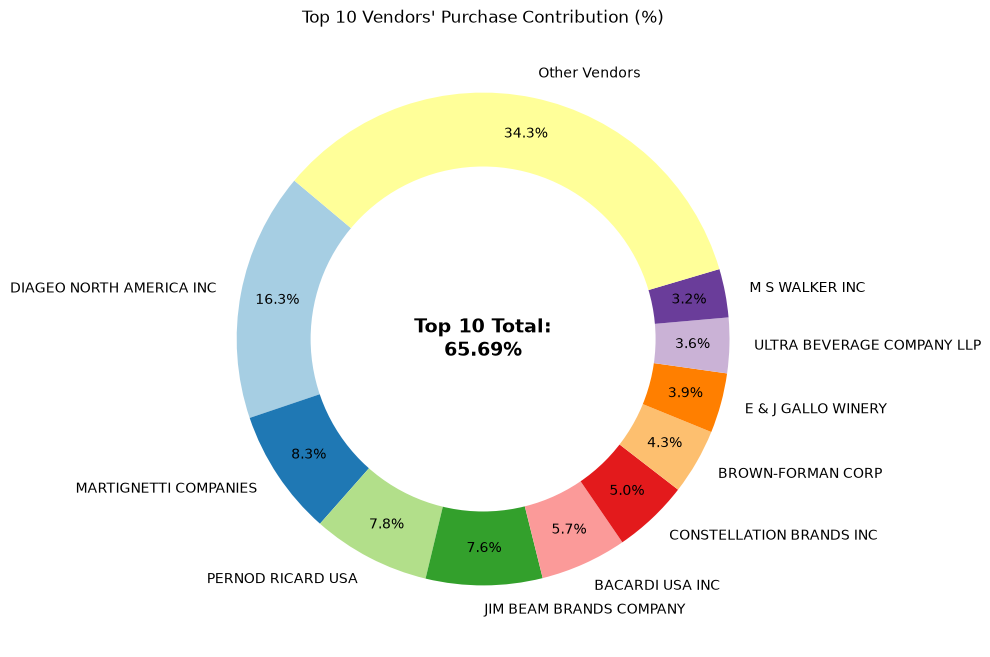

In [16]:
total_contribution = top_vendors["PurchaseContribution%"].sum()
print(f"Total purchase contribution of top 10 vendors: {total_contribution:.2f}%")

vendors = list(top_vendors["VendorName"]) + ["Other Vendors"]
contributions = list(top_vendors["PurchaseContribution%"]) + [100 - total_contribution]

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(contributions, labels=vendors, autopct="%1.1f%%", startangle=140,
       pctdistance=0.85, colors=plt.cm.Paired.colors)
fig.gca().add_artist(plt.Circle((0, 0), 0.70, fc="white"))  # donut hole
plt.text(0, 0, f"Top 10 Total:\n{total_contribution:.2f}%", fontsize=14,
         fontweight="bold", ha="center", va="center")
plt.title("Top 10 Vendors' Purchase Contribution (%)")
save("09_donut_top10_share")

Two-thirds of spend sits with 10 suppliers → **concentration risk**. Diversifying suppliers
and negotiating with the top ones are both levers.

## Q5 · Does buying in bulk lower the unit price?

In [17]:
df["UnitPurchasePrice"] = df["TotalPurchaseDollars"] / df["TotalPurchaseQuantity"]
df["OrderSize"] = pd.qcut(df["TotalPurchaseQuantity"], q=3, labels=["Small", "Medium", "Large"])
unit_price_by_size = df.groupby("OrderSize", observed=True)["UnitPurchasePrice"].mean()
display(unit_price_by_size)
reduction = (1 - unit_price_by_size["Large"] / unit_price_by_size["Small"]) * 100
print(f"Large orders pay {reduction:.0f}% less per unit than small orders")

OrderSize
Small     39.068186
Medium    15.486414
Large     10.777625
Name: UnitPurchasePrice, dtype: float64

Large orders pay 72% less per unit than small orders


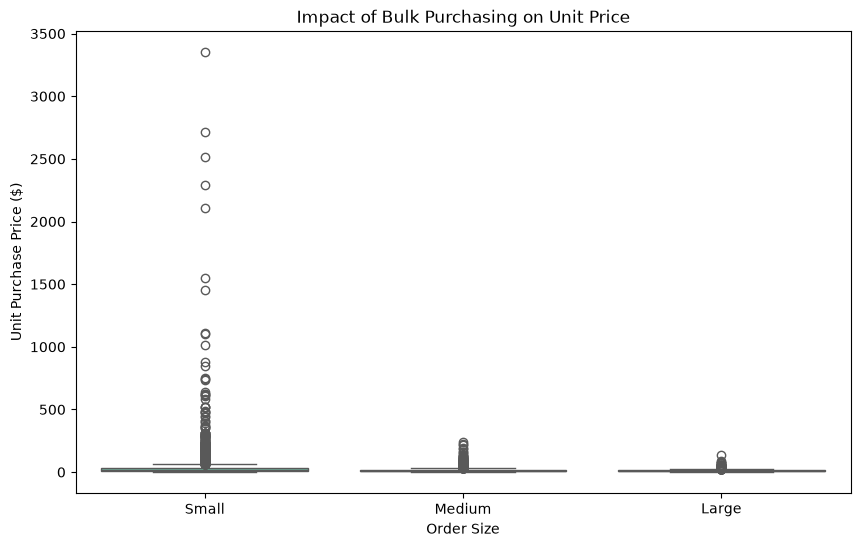

In [18]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="OrderSize", y="UnitPurchasePrice", palette="Set2")
plt.title("Impact of Bulk Purchasing on Unit Price")
plt.xlabel("Order Size")
plt.ylabel("Unit Purchase Price ($)")
save("10_bulk_purchasing")

- Large orders get the lowest unit price (~$10.78 vs ~$39.07 for small orders, ~72% less).
- Bulk pricing works: buying more per order lowers cost and lifts margin — as long as the
  extra stock actually sells (see Q6, Q7).

## Q6 · Which vendors have slow-moving stock (turnover < 1)?

In [19]:
slow_vendors = (
    df[df["StockTurnover"] < 1]
    .groupby("VendorName")[["StockTurnover"]].mean()
    .sort_values("StockTurnover")
    .head(10)
)
display(slow_vendors)

,StockTurnover
VendorName,
ALISA CARR BEVERAGES,0.615385
HIGHLAND WINE MERCHANTS LLC,0.708333
PARK STREET IMPORTS LLC,0.751306
Circa Wines,0.755676
Dunn Wine Brokers,0.766022
CENTEUR IMPORTS LLC,0.773953
SMOKY QUARTZ DISTILLERY LLC,0.783835
TAMWORTH DISTILLING,0.797078
THE IMPORTED GRAPE LLC,0.807569


## Q7 · How much capital is locked in unsold inventory?

In [20]:
df["UnsoldInventoryValue"] = (df["TotalPurchaseQuantity"] - df["TotalSalesQuantity"]) * df["PurchasePrice"]
print("Total unsold capital:", format_dollars(df["UnsoldInventoryValue"].sum()))

inventory_value_per_vendor = (
    df.groupby("VendorName")["UnsoldInventoryValue"].sum()
    .sort_values(ascending=False)
    .reset_index()
)
display(inventory_value_per_vendor.head(10).assign(
    UnsoldInventoryValue=lambda t: t["UnsoldInventoryValue"].apply(format_dollars)))

Total unsold capital: 2.71M


,VendorName,UnsoldInventoryValue
0,DIAGEO NORTH AMERICA INC,722.21K
1,JIM BEAM BRANDS COMPANY,554.67K
2,PERNOD RICARD USA,470.63K
3,WILLIAM GRANT & SONS INC,401.96K
4,E & J GALLO WINERY,228.28K
5,SAZERAC CO INC,198.44K
6,BROWN-FORMAN CORP,177.73K
7,CONSTELLATION BRANDS INC,133.62K
8,MOET HENNESSY USA INC,126.48K
9,REMY COINTREAU USA INC,118.60K


## Q8 · Do high-selling and low-selling products earn different margins?
Each row is a vendor + product. "Top" = top 25% by sales $, "low" = bottom 25%.

### 95% confidence intervals

Top sellers 95% CI: (30.74, 31.61), mean 31.18
Low sellers 95% CI: (40.50, 42.64), mean 41.57


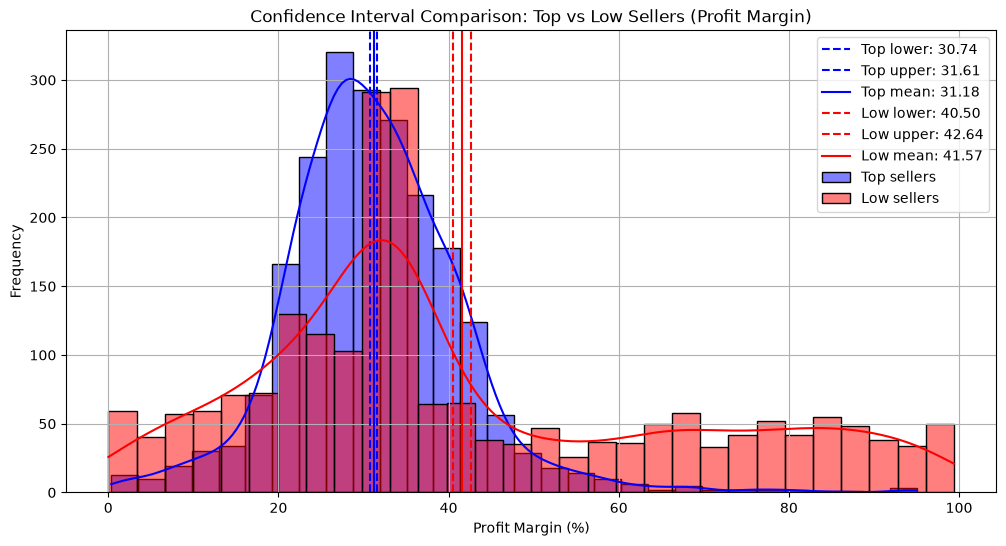

In [21]:
top_threshold = df["TotalSalesDollars"].quantile(0.75)
low_threshold = df["TotalSalesDollars"].quantile(0.25)
top_products = df[df["TotalSalesDollars"] >= top_threshold]["ProfitMargin"].dropna()
low_products = df[df["TotalSalesDollars"] <= low_threshold]["ProfitMargin"].dropna()


def confidence_interval(data, confidence=0.95):
    """Mean and t-based confidence interval."""
    mean_val = np.mean(data)
    std_err = np.std(data, ddof=1) / np.sqrt(len(data))
    t_critical = stats.t.ppf((1 + confidence) / 2, df=len(data) - 1)
    margin = t_critical * std_err
    return mean_val, mean_val - margin, mean_val + margin


top_mean, top_lower, top_upper = confidence_interval(top_products)
low_mean, low_lower, low_upper = confidence_interval(low_products)
print(f"Top sellers 95% CI: ({top_lower:.2f}, {top_upper:.2f}), mean {top_mean:.2f}")
print(f"Low sellers 95% CI: ({low_lower:.2f}, {low_upper:.2f}), mean {low_mean:.2f}")

plt.figure(figsize=(12, 6))
for data, color, label, (m, lo, hi) in [
    (top_products, "blue", "Top", (top_mean, top_lower, top_upper)),
    (low_products, "red", "Low", (low_mean, low_lower, low_upper)),
]:
    sns.histplot(data, kde=True, color=color, bins=30, alpha=0.5, label=f"{label} sellers")
    plt.axvline(lo, color=color, linestyle="--", label=f"{label} lower: {lo:.2f}")
    plt.axvline(hi, color=color, linestyle="--", label=f"{label} upper: {hi:.2f}")
    plt.axvline(m, color=color, linestyle="-", label=f"{label} mean: {m:.2f}")
plt.title("Confidence Interval Comparison: Top vs Low Sellers (Profit Margin)")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
save("11_profit_margin_ci")

- Low sellers' margin CI (~40.5%–42.6%) sits well above top sellers' (~30.7%–31.6%).
- Low sellers likely rely on premium pricing; top sellers compete on price and volume.
- **Top sellers:** look at selective price changes, cost cuts or bundling to lift margin.
- **Low sellers:** good margins but little volume → marketing, distribution or pricing help.

### Hypothesis test (Welch's two-sample t-test)
- **H0:** no difference in mean profit margin between top and low sellers.
- **H1:** the mean margins are different.

In [22]:
t_stat, p_value = ttest_ind(top_products, low_products, equal_var=False)
print(f"T-statistic: {t_stat:.4f}, p-value: {p_value:.4g}")
if p_value < 0.05:
    print("Reject H0: profit margins of top and low sellers are significantly different.")
else:
    print("Fail to reject H0: no significant difference in profit margins.")

T-statistic: -17.6695, p-value: 2.297e-66
Reject H0: profit margins of top and low sellers are significantly different.


In [23]:
conn.close()